# GraphGuard: Phát Hiện Rửa Tiền (IBM AML) Bằng Graph Analytics & Machine Learning

> **MỤC ĐÍCH NOTEBOOK TRÌNH CHIẾU (PRESENTATION DEMO):**
> Notebook này được thiết kế cô đọng, bám sát **100% yêu cầu Phần Thực Hành (Part B — Section 4 & Section 5)** của đề bài môn Big Data trên bộ dữ liệu **IBM AML HI-Small (Giao dịch rửa tiền liên ngân hàng đa tiền tệ)**:
> 1. **Live Code & Thuật toán cốt lõi:** Chạy trực tiếp trên tập mẫu kiểm chứng (~100k giao dịch tại `data/processed/sample/ibm_aml/`), minh họa tường minh từ quy trình **ETL ghép khóa phức hợp `Bank_Account` & Defensive Vertices (Task 1)**, **Phân phối bậc, Self-loops & PageRank (Task 2)**, **Truy vấn chu trình rửa tiền khép kín 3-Cycle (Task 3b)**, **Phát hiện cộng đồng LPA & Phân tích Tightly-Knit Clusters đa ngân hàng (Task 4)**, đến pipeline mở rộng **Trích xuất đặc trưng Strict-Past & Huấn luyện Decision Tree Walk-Forward (Chặng 3–5)**.
> 2. **Kết quả khoa học chính thức:** Đọc và đối chiếu tự động với checkpoint đã nghiệm thu trên toàn bộ **5.078.345 giao dịch full dataset** (`results/presentation_checkpoint/ibm_aml/`).
>
> ⚠️ **TUYÊN BỐ TRUNG THỰC (HONEST DISCLOSURE):**
> - Mẫu sample (~100k dòng, degree trung bình 1.68) thưa hơn rất nhiều so với full dataset (5.08M dòng, degree trung bình 19.59). Do đó số lượng 3-cycle trên sample có thể rất ít hoặc bằng 0; đây là hệ quả tất yếu của việc lấy mẫu, không phải đặc tính của toàn bộ tập dữ liệu IBM.
> - Kết quả Full Run cho thấy `full_fusion` (T + C + M + L) **không làm tăng F1** (15.27% -> 14.80%), nhưng mang lại giá trị thực tế quan trọng: **giảm gần 50% số lượng cảnh báo (alerts)** (alerts giảm từ 9,584 xuống 4,956), giúp tăng độ chuẩn xác trong ngân sách điều tra eo hẹp.

---
## 0. GIỚI THIỆU 2 BỘ DỮ LIỆU & VAI TRÒ KIỂM CHỨNG CỦA IBM AML HI-SMALL (SECTION 4)

Trong dự án này, **PaySim** đóng vai trò bộ dữ liệu chính (Primary Dataset) và **IBM AML HI-Small** đóng vai trò bộ dữ liệu kiểm chứng bổ sung (Complementary Validation Dataset):

| Tiêu chí đối chiếu | Dataset 1: PaySim (Mobile Money — Primary) | Dataset 2: IBM AML HI-Small (Multi-Bank — Validation) |
| :--- | :--- | :--- |
| **Quy mô toàn bộ (Full Dataset)** | **6,362,620** giao dịch (cạnh `E`) / **9,073,900** tài khoản (đỉnh `V`) | **5,078,345** giao dịch (cạnh `E`) / **518,581** tài khoản (đỉnh `V`) |
| **Số giao dịch bất thường (Prevalence)** | **8,213** giao dịch gian lận (**0.129%**) | **5,177** giao dịch rửa tiền (**0.102%**) |
| **Đơn vị thời gian & Tiền tệ** | Bước giờ mô phỏng `step` (1–744 giờ = 30 ngày), 1 đơn vị tiền | `Timestamp` thực (epoch seconds), **15 loại tiền tệ**, đa ngân hàng |
| **Bậc trung bình & Tự nối (Self-loops)** | Trung bình **1.40** cạnh/đỉnh (đồ thị cực thưa) / **0** self-loops | Trung bình **19.59** cạnh/đỉnh (mạng liên kết dày) / **591,212** self-loops (~11.64%) |
| **Chu trình có hướng 3 đỉnh (3-Cycles)** | **0 chu trình** (cấu trúc *Star-Forest* phi chu trình) | **54 chu trình tài khoản có hướng** (**2,491** tổ hợp giao dịch vòng tròn) |
| **Cấu trúc cộng đồng LPA (Internal vs. Cross)** | **5,433,491** cụm; Top 50 cụm có **0 cạnh nội cụm** (100% cạnh liên cụm) | **314,722** cụm; có tới **852,930 cạnh nội cụm** (Tightly-knit clusters) |

### 📌 Tại sao IBM AML HI-Small giải quyết được hạn chế cấu trúc của PaySim:
1. **Vấn đề của PaySim:** PaySim chỉ mô phỏng gian lận đánh cắp tài khoản ví di động đơn lẻ (`TRANSFER -> CASH_OUT`), tạo ra đồ thị hình sao phi chu trình (**0 chu trình 3 đỉnh** và **0 giao dịch nội cụm** ở các cộng đồng lớn).
2. **Giải pháp từ IBM AML HI-Small:** Được sinh từ bộ mô phỏng đa tác nhân (Multi-Agent Simulator) mô tả dòng tiền rửa tiền liên ngân hàng với **8 typology chuẩn** (*Cycle, Fan-In, Fan-Out, Gather-Scatter, Scatter-Gather, Stack, Bipartite, Random*), IBM AML chứa:
   - **54 chu trình tài khoản 3 đỉnh có hướng (`A -> B -> C -> A`)** với **2,491 tổ hợp giao dịch rửa tiền** để kiểm chứng trực tiếp thuật toán GraphFrames Motif Finding (Task 3b).
   - **Các cụm tài khoản giao dịch nội bộ khép kín (Tightly-Knit Clusters)** trải rộng qua nhiều ngân hàng với hơn **852 nghìn giao dịch nội cụm**, cho phép đánh giá sâu sắc thuật toán LPA (Task 4).


---
### CHẶNG 1 (TASK 1 — 15 ĐIỂM): XÂY DỰNG ĐỒ THỊ LIÊN NGÂN HÀNG (`GRAPHFRAME`) & KIỂM TRA TOÀN VẸN
#### 1.1 Kỹ Thuật ETL IBM AML: Khóa Phức Hợp `Bank_Account` & Defensive Vertex Generation
*Lời trình bày:* Bảng CSV gốc của IBM AML (`HI-Small_Trans.csv`) đặt ra 3 bài toán kỹ thuật đặc thù mà bước ETL (Task 1) phải giải quyết trước khi dựng `GraphFrame(vertices, edges)`:
1. **Trùng tên cột `Account`:** File gốc có 2 cột cùng tên `Account` (1 cho bên gửi và 1 cho bên nhận), cần đổi tên tường minh thành `Account` và `Account_Dest`.
2. **Chống va chạm định danh liên ngân hàng (Composite ID `Bank_Account`):** Hai ngân hàng khác nhau có thể cấp cùng một mã tài khoản. Do đó khóa đỉnh bắt buộc phải ghép `F.concat_ws("_", F.col("From Bank"), F.col("Account"))`.
3. **Defensive Vertex Generation:** Hợp nhất (`unionByName` + `dropDuplicates(["id"])`) toàn bộ đỉnh xuất hiện ở cả chiều gửi (`src`) lẫn chiều nhận (`dst`) kèm `bank_id` để đảm bảo **0 dangling edges**.


In [1]:
# Cell C1a: Preflight, Spark Initialization & Raw-to-GraphFrame ETL Demonstration for IBM AML (Task 1)
import os
import sys
import time
import tempfile
import atexit
import json
import hashlib
import pandas as pd
import platform
from pathlib import Path
from dataclasses import dataclass, field
from contextlib import contextmanager
from IPython.display import Image, display

# 1. Tìm gốc repository tự động
current_dir = Path(os.getcwd()).resolve()
repo_root = current_dir
while not (repo_root / "src" / "common" / "spark_session.py").exists():
    if repo_root.parent == repo_root:
        raise FileNotFoundError("Không tìm thấy gốc repository chứa src/common/spark_session.py")
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print(f"[PREFLIGHT] Gốc repository: {repo_root}")

if os.name != "nt" or sys.version_info[:2] != (3, 12):
    raise RuntimeError("Chạy bằng Windows Python 3.12 trong .venv của repository.")
if not os.path.samefile(sys.executable, repo_root / ".venv/Scripts/python.exe"):
    raise RuntimeError("Chọn kernel GraphGuard (.venv Windows).")

# 2. Kiểm tra môi trường (Python, Java, các thư viện phụ thuộc)
print(f"[PREFLIGHT] Python interpreter: {sys.version.split()[0]} ({sys.executable})")
java_home = os.environ.get("JAVA_HOME", "")
print(f"[PREFLIGHT] JAVA_HOME: {java_home if java_home else 'Chưa set JAVA_HOME (sử dụng PATH hệ thống)'}")

for pkg_name in ["pyspark", "graphframes", "pandas", "matplotlib", "IPython"]:
    try:
        __import__(pkg_name)
        print(f"  • Thư viện {pkg_name:<12}: [OK]")
    except ImportError as e:
        raise ImportError(f"Thiếu thư viện bắt buộc '{pkg_name}'. Vui lòng kích hoạt .venv và cài đặt requirements.txt!") from e

# 3. Kiểm tra tài nguyên và đường dẫn đầu vào
sample_dir = repo_root / "data" / "processed" / "sample" / "ibm_aml"
checkpoint_dir = repo_root / "results" / "presentation_checkpoint" / "ibm_aml"

assert (sample_dir / "vertices.parquet").exists(), f"Thiếu file {sample_dir / 'vertices.parquet'}"
assert (sample_dir / "edges.parquet").exists(), f"Thiếu file {sample_dir / 'edges.parquet'}"
assert checkpoint_dir.exists(), f"Thiếu thư mục checkpoint: {checkpoint_dir}"

# Xác thực các artifacts full được dùng; không thay đổi chúng.
checkpoint_root = checkpoint_dir.parent
manifest = json.loads((checkpoint_root / "MANIFEST.json").read_text(encoding="utf-8"))
def verify_checkpoint(relative):
    entry = manifest[relative]
    data = (checkpoint_root / relative).read_bytes()
    actual = hashlib.sha256(data).hexdigest()
    mode = "exact bytes"
    if actual != entry["sha256"]:
        assert Path(relative).suffix.lower() in {".csv", ".json", ".md"}, relative
        lf = data.replace(b"\r\n", b"\n")
        candidates = {"checkout LF; source CRLF": lf.replace(b"\n", b"\r\n"),
                      "checkout CRLF; source LF": lf}
        matches = [name for name, raw in candidates.items()
                   if hashlib.sha256(raw).hexdigest() == entry["sha256"] and len(raw) == entry["bytes"]]
        assert matches, f"Checkpoint content changed: {relative}"
        mode = matches[0]
    else:
        assert len(data) == entry["bytes"], relative
    return {"actual_sha256": actual, "source_sha256": entry["sha256"], "verification": mode}

verified_checkpoints = {relative: verify_checkpoint(relative)
                        for relative in manifest if relative.startswith(("ibm_aml/", "common/"))}
from collections import Counter
print("[CHECKPOINT VERIFICATION]", dict(Counter(v["verification"] for v in verified_checkpoints.values())))
input_sha256 = {
    path.relative_to(repo_root).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
    for path in sorted(sample_dir.rglob("*.parquet")) if path.is_file()
}
assert input_sha256, "Không có sample Parquet đầu vào"
print("[INPUT SHA256]", json.dumps(input_sha256, ensure_ascii=False))

# 4. Tạo thư mục tạm an toàn
temp_scratch_obj = tempfile.TemporaryDirectory(prefix="gg_ibm_demo_")
temp_scratch = Path(temp_scratch_obj.name)
atexit.register(temp_scratch_obj.cleanup)
print(f"[TEMP] Scratch directory độc lập: {temp_scratch}")

@contextmanager
def timed(label: str):
    t0 = time.perf_counter()
    yield
    print(f"  [{label}] Hoàn thành trong {time.perf_counter() - t0:.2f}s")

# 5. Khởi tạo SparkSession có Hardware Guard
from pyspark.sql import functions as F
from graphframes import GraphFrame
from src.common.spark_session import get_graph_session
from src.common.graph_utils import load_graph, check_integrity
from src.ibm_aml.etl import build_ibm_edges, build_ibm_vertices

with timed("Khởi tạo SparkSession"):
    spark = get_graph_session(
        app_name="GraphGuard-IBM-Presentation",
        driver_memory="5g",
        shuffle_partitions=16,
        checkpoint_dir=str(temp_scratch / "spark_checkpoints"),
        extra_configs={
            "spark.hadoop.parquet.block.size": str(32 * 1024 * 1024),
            "spark.sql.parquet.columnarReaderBatchSize": "1024",
            "spark.sql.inMemoryColumnarStorage.batchSize": "1000",
            "spark.ui.showConsoleProgress": "false",
        }
    )

assert spark.sparkContext._jvm.java.lang.System.getProperty("java.version").split(".")[0] == "17"
from src.common import hardware_guard
print("[RUNTIME]", platform.platform(), "Spark", spark.version, "Java", os.environ["JAVA_HOME"])
print("[RESOURCE]", json.dumps(hardware_guard._GUARD.snapshot()))

# Hàm materialize dùng Parquet để cắt lineage; không dùng localCheckpoint.
def stage(frame, name):
    path = temp_scratch / (name + ".parquet")
    frame.write.mode("overwrite").parquet(str(path))
    return spark.read.parquet(str(path))

# 6. MINH HỌA KỸ THUẬT ETL (TASK 1): Biến đổi 1,000 dòng giao dịch ở Raw Schema IBM AML -> GraphFrame(vertices, edges)
with timed("Minh họa ETL từ 1,000 dòng Raw Schema IBM AML sang GraphFrame"):
    raw_sample_edges = spark.read.parquet(str(sample_dir / "edges.parquet")).limit(1000)
    
    # Tái lập bảng giao dịch thô đúng định dạng CSV gốc của IBM AML (From Bank, Account, To Bank, Account_Dest...)
    raw_ibm_df = raw_sample_edges.select(
        F.date_format(F.col("timestamp"), "yyyy/MM/dd HH:mm").alias("Timestamp"),
        F.split(F.col("src"), "_").getItem(0).alias("From Bank"),
        F.split(F.col("src"), "_").getItem(1).alias("Account"),
        F.split(F.col("dst"), "_").getItem(0).alias("To Bank"),
        F.split(F.col("dst"), "_").getItem(1).alias("Account_Dest"),
        F.col("amount_received").alias("Amount Received"),
        F.col("receiving_currency").alias("Receiving Currency"),
        F.col("amount").alias("Amount Paid"),
        F.col("payment_currency").alias("Payment Currency"),
        F.col("type").alias("Payment Format"),
        F.col("isFraud").alias("Is Laundering"),
    )
    
    # [A] Xây dựng Edges DF: Ghép khóa phức hợp Bank_Account để chống đụng độ ID tài khoản giữa các ngân hàng
    ts_col = F.to_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm")
    e_raw_demo = raw_ibm_df.select(
        F.concat_ws("_", F.col("From Bank"), F.col("Account")).alias("src"),
        F.concat_ws("_", F.col("To Bank"), F.col("Account_Dest")).alias("dst"),
        F.col("Amount Paid").cast("double").alias("amount"),
        F.col("Payment Currency").alias("payment_currency"),
        ts_col.cast("long").cast("int").alias("step"),
        F.col("Payment Format").alias("type"),
        F.col("Is Laundering").cast("short").alias("isFraud"),
    )
    
    # [B] Xây dựng Vertices DF (Defensive Vertex Generation): Hợp nhất mọi đỉnh từ cả src và dst để bảo đảm 0 dangling edges
    src_verts = raw_ibm_df.select(
        F.concat_ws("_", F.col("From Bank"), F.col("Account")).alias("id"),
        F.col("From Bank").alias("bank_id"),
    )
    dst_verts = raw_ibm_df.select(
        F.concat_ws("_", F.col("To Bank"), F.col("Account_Dest")).alias("id"),
        F.col("To Bank").alias("bank_id"),
    )
    v_raw_demo = (
        src_verts.unionByName(dst_verts)
        .dropDuplicates(["id"])
        .withColumn("account_type", F.lit("Account"))
        .withColumn("balance", F.lit(0.0).cast("double"))
        .select("id", "account_type", "bank_id", "balance")
    )
    
    # [C] Khởi tạo GraphFrame & đối chiếu với hàm chuẩn trong src.ibm_aml.etl
    g_raw_demo = GraphFrame(v_raw_demo, e_raw_demo)
    ref_e_demo = build_ibm_edges(raw_ibm_df)
    ref_v_demo = build_ibm_vertices(raw_ibm_df, ref_e_demo)
    assert g_raw_demo.vertices.count() == ref_v_demo.count() and g_raw_demo.edges.count() == ref_e_demo.count()

print("\n[TASK 1 — DEMO ETL TRÊN 1,000 DÒNG GIAO DỊCH THÔ IBM AML]:")
print(f"  • Input Raw DataFrame : {raw_ibm_df.count():,} giao dịch -> Output GraphFrame: {g_raw_demo.vertices.count():,} đỉnh, {g_raw_demo.edges.count():,} cạnh")
print("  • 5 dòng mẫu Vertices DF (Khóa phức hợp id = Bank_Account, bank_id, account_type):")
g_raw_demo.vertices.show(5, truncate=False)
print("  • 5 dòng mẫu Edges DF (src, dst, amount, payment_currency, step, type, isFraud):")
g_raw_demo.edges.show(5, truncate=False)


#### 1.2 Nạp Đồ Thị `sample_100k`, Kiểm Tra Toàn Vẹn & Đối Chiếu Với Full Dataset
*Lời trình bày:* Nạp đồ thị `sample_100k`, kiểm tra tự động các điều kiện toàn vẹn cấu trúc (**0 null IDs, 0 dangling edges**), thống kê tỷ lệ giao dịch tự nối (**Self-loops ~11.8%** do giao dịch tái đầu tư / chuyển đổi ngoại tệ nội bộ) và đối chiếu với **5.08 triệu giao dịch Full Dataset**.


In [2]:
# Cell C1b: Load Sample GraphFrame, Integrity Check & Full-Dataset Reconciliation
graph = load_graph(spark, str(sample_dir))
v_count = graph.vertices.count()
e_count = graph.edges.count()

print(f"[GRAPH LOADED] GraphFrame IBM AML Sample:")
print(f"  • Số lượng đỉnh (|V| - tài khoản/ngân hàng): {v_count:,}")
print(f"  • Số lượng cạnh (|E| - giao dịch): {e_count:,}")
print(f"  • Schema cạnh:")
graph.edges.printSchema()

assert e_count > 0 and v_count > 0
integrity = check_integrity(graph)
assert all(integrity[key] == 0 for key in ("null_vertices", "null_edges", "dangling_edges"))
assert graph.vertices.select("id").distinct().count() == v_count

# Đối chiếu trực tiếp với bảng tổng quan Full Dataset từ checkpoint nghiệm thu
overview_df = pd.read_csv(checkpoint_root / "common" / "tables" / "dataset_overview.csv")
print("\n[BẢNG ĐỐI CHIẾU QUY MÔ & CẤU TRÚC TOÀN BỘ 2 BỘ DỮ LIỆU (FULL RUN CHECKPOINT)]:")
print(overview_df[["dataset", "transactions", "accounts", "positives", "prevalence", "self_loops", "mean_total_degree", "communities", "internal_edges", "cross_edges"]].to_string(index=False))
print("\n[SAMPLE] Dữ liệu sample_100k chạy live; các bảng/biểu đồ Full Run được đối chiếu trực tiếp từ checkpoint.")


---
### CHẶNG 2 (TASKS 2, 3, 4 — 50 ĐIỂM): ĐỘ ĐO CẤU TRÚC, PAGERANK, CỘNG ĐỒNG LPA & MOTIF CHU TRÌNH
#### 2.1 Phân Phối Bậc (`inDegrees`, `outDegrees`, `degrees`), Self-Loops & Quy Luật Power-Law (Task 2a)
*Lời trình bày:* Khác với PaySim, dữ liệu IBM AML có tỷ lệ tự giao dịch (`self-loop`, ví dụ tái đầu tư *Reinvestment*) chiếm ~11.8%. Mỗi self-loop đóng góp 1 vào `inDegree` và 1 vào `outDegree`, bảo toàn định lý Euler (`Σ degree = 2 * |E|`). Trên toàn bộ 5.08M giao dịch, mạng IBM AML có mật độ kết nối dày hơn hẳn PaySim (bậc trung bình **19.59** so với **1.40**) và thể hiện rõ phân phối đuôi dài (**Power-Law**).


In [3]:
# Cell C2: Degree Calculation, Self-Loops Invariant (Σ degree = 2|E|) & Power-Law Distribution (Task 2a)
from pyspark.sql import functions as F

def account_degree_metrics(ids, edges):
    incoming = edges.groupBy("dst").count().select(F.col("dst").alias("id"), F.col("count").alias("inDegree"))
    outgoing = edges.groupBy("src").count().select(F.col("src").alias("id"), F.col("count").alias("outDegree"))
    return (
        ids.join(incoming, "id", "left").join(outgoing, "id", "left")
        .fillna(0, subset=["inDegree", "outDegree"])
        .withColumn("degree", F.col("inDegree") + F.col("outDegree"))
    )

with timed("Tính toán Degree Metrics & Self-loops"):
    self_loops = graph.edges.where(F.col("src") == F.col("dst")).count()
    deg_df = account_degree_metrics(graph.vertices.select("id"), graph.edges)
    totals = deg_df.agg(F.count("*").alias("v_total"), F.sum("degree").alias("degree_sum")).first()

print(f"[DEGREE & SELF-LOOPS CHECK TRÊN SAMPLE]")
print(f"  • Số lượng self-loops (src == dst): {self_loops:,} ({self_loops / e_count * 100:.2f}%)")
print(f"  • Tổng bậc Σ degree: {int(totals.degree_sum):,}")
print(f"  • 2 * Số cạnh (2|E|): {2 * e_count:,}")
assert int(totals.degree_sum) == 2 * e_count, "Bất biến cấu trúc vi phạm: Tổng degree != 2|E|!"
print("  => [PASS] Đồ thị bảo toàn toàn vẹn liên kết Euler.")

print("\n[TOP 5 TÀI KHOẢN CÓ TỔNG BẬC CAO NHẤT TRÊN SAMPLE]:")
deg_df.orderBy(F.desc("degree")).show(5)

# Đối chiếu phân phối bậc trên Full Dataset IBM AML (518,581 tài khoản)
full_deg_dist = pd.read_csv(checkpoint_dir / "tables" / "degree_distribution.csv")
print("[PHÂN PHỐI BẬC TRÊN FULL DATASET IBM AML (518,581 TÀI KHOẢN — TOP 5 MỨC BẬC ĐẦU & ĐUÔI HUB)]:")
print(pd.concat([full_deg_dist.head(5), full_deg_dist.tail(5)]).to_string(index=False))

for fig_title, fig_path in [
    ("Biểu đồ Phân phối Bậc Full IBM AML (Log-Log Scale)", checkpoint_dir / "figures" / "full_degree.png"),
    ("So sánh Phân phối Bậc Power-Law: PaySim vs. IBM AML", checkpoint_root / "common" / "comparison" / "degree_distribution_paysim_vs_ibm.png"),
]:
    if fig_path.exists():
        print(f"\n[{fig_title}]:")
        display(Image(filename=str(fig_path), width=680))


#### 2.2 Thuật Toán PageRank Đa Cạnh & Kiểm Chứng AML Caveat (Task 2b)
*Lời trình bày:* Triển khai thuật toán PageRank bảo toàn trọng số cạnh đa vật lý (`multiplicity`) và self-loops (10 vòng lặp, `resetProbability = 0.15`). Ta hiển thị **Top 10 tài khoản có PageRank cao nhất trên Full Dataset IBM AML** và kiểm chứng lưu ý của đề bài: **PageRank cao đánh dấu các tài khoản định chế/doanh nghiệp nhận thanh toán từ hàng trăm đối tác, không tự động hàm ý rửa tiền.**


In [4]:
# Cell C3: Directed PageRank Algorithm & Top 10 AML Caveat Verification (Task 2b)
from src.paysim.metrics import pagerank_update, dataframe_pagerank

def inline_pagerank(vertices, edges, iterations=10, reset_probability=0.15):
    ids = vertices.select("id")
    links = edges.groupBy("src", "dst").agg(F.count("*").cast("double").alias("multiplicity"))
    outgoing = links.groupBy("src").agg(F.sum("multiplicity").alias("outgoing"))
    weights = links.join(outgoing, "src").select("src", "dst", (F.col("multiplicity") / F.col("outgoing")).alias("weight"))
    
    weights = stage(weights, "inline_pr_weights")
    ranks = ids.withColumn("pagerank", F.lit(1.0))
    for i in range(iterations):
        ranks = stage(pagerank_update(ids, weights, ranks, reset_probability), f"inline_pr_{i+1:02d}")
        
    totals = ranks.agg(F.count("*").alias("n"), F.sum("pagerank").alias("rank_sum")).first()
    return ranks.withColumn("pagerank", F.col("pagerank") * F.lit(totals.n / totals.rank_sum))

with timed("Chạy PageRank Inline 10 vòng lặp"):
    pr_ranks = stage(inline_pagerank(graph.vertices, graph.edges, iterations=10), "inline_pr_final")
    pr_sum = pr_ranks.agg(F.sum("pagerank")).first()[0]

print(f"[PAGERANK CONVERGENCE TRÊN SAMPLE]")
print(f"  • Tổng PageRank sau chuẩn hóa: {pr_sum:,.2f} (Kỳ vọng: {v_count:,.2f})")
assert abs(pr_sum - v_count) < 1e-4 * v_count, "PageRank normalization failed"

# Hậu kiểm (Post-hoc Audit) số giao dịch rửa tiền của Top 5 PageRank trên Sample
fraud_in_sample = graph.edges.where(F.col("isFraud") == 1).groupBy(F.col("dst").alias("id")).agg(F.count("*").alias("incoming_laundering_tx"))
fraud_out_sample = graph.edges.where(F.col("isFraud") == 1).groupBy(F.col("src").alias("id")).agg(F.count("*").alias("outgoing_laundering_tx"))
top_pr_sample = (
    pr_ranks.join(deg_df, "id", "left")
    .join(fraud_out_sample, "id", "left")
    .join(fraud_in_sample, "id", "left")
    .fillna(0, subset=["outgoing_laundering_tx", "incoming_laundering_tx"])
)
print("\n[TOP 5 TÀI KHOẢN PAGERANK TRÊN SAMPLE KÈM ĐỐI CHIẾU RỬA TIỀN]:")
top_pr_sample.orderBy(F.desc("pagerank")).show(5)

# Đối chiếu với implementation chuẩn trong module src (truyền cạnh label-blind src, dst)
with timed("Đối chiếu PageRank với module src"):
    unlabelled_edges = graph.edges.select("src", "dst")
    ref_ranks = dataframe_pagerank(graph.vertices, unlabelled_edges, temp_scratch / "pr_check", iterations=10)
    diff_max = pr_ranks.join(ref_ranks.select(F.col("id"), F.col("pagerank").alias("ref_pr")), "id") \
        .agg(F.max(F.abs(F.col("pagerank") - F.col("ref_pr")))).first()[0]
    assert diff_max is not None and diff_max < 1e-8, f"PageRank mismatch: {diff_max}"
    print(f"  • Sai khác tuyệt đối cực đại giữa bản inline và src: {diff_max:.2e} (Thuật toán đồng nhất)")

# Hiển thị Bảng Top 10 PageRank trên Full Dataset IBM AML (518,581 đỉnh)
top10_full_pr = pd.read_csv(checkpoint_dir / "tables" / "top10_pagerank.csv")
print("\n[TOP 10 TÀI KHOẢN CÓ PAGERANK CAO NHẤT TRÊN FULL DATASET IBM AML (518,581 ĐỈNH)]:")
print(top10_full_pr.to_string(index=False))
print("  => NHẬN XÉT NGHIỆP VỤ (AML CAVEAT): Đứng đầu là tài khoản 40836_80F47A310 (PageRank = 92.92, inDegree = 159, outDegree = 2).")
print("     Tất cả Top 10 đỉnh có PageRank cao nhất đều có inDegree rất lớn (69 -> 159) nhưng outDegree chỉ từ 1 đến 2.")
print("     Đây là cấu trúc điển hình của tài khoản thu hộ/định chế thương mại lớn chứ không phải mắt xích rửa tiền luân chuyển vòng tròn.")

pr_fig = checkpoint_dir / "figures" / "full_pagerank.png"
if pr_fig.exists():
    display(Image(filename=str(pr_fig), width=680))


#### 2.3 Phát Hiện Cộng Đồng (LPA) & Phân Tích Tightly-Knit Clusters Đa Ngân Hàng (Task 4 — 25 Điểm)
*Lời trình bày:* Thuật toán LPA đồng bộ cập nhật nhãn theo đa số phiếu láng giềng (hòa phiếu ưu tiên nhãn số nhỏ nhất). Trên mạng liên ngân hàng IBM AML, ta đi sâu phân tích **Tightly-Knit Clusters (Cụm liên kết chặt)**:
1. Định lượng **độ đa dạng ngân hàng (`unique_banks_count`)**, số lượng **giao dịch nội cụm (`internal_tx_count`: `src_label == dst_label`)** so với **liên cụm (`cross_tx_count`)**.
2. Nhận diện cả **các siêu cụm điểm nóng rửa tiền (Fraud Hotspots)** lẫn **các cụm khép kín có tỷ lệ giao dịch nội bộ ~98%**.


In [5]:
# Cell C4: Community Detection (LPA) & Multi-Bank Tightly-Knit Cluster Profiling (Task 4)
from src.paysim.community_detection import lpa_update, dataframe_lpa

def inline_lpa(vertices, edges, max_iter=5):
    links = (edges.select(F.col("src").alias("id"), F.col("dst").alias("neighbor"))
        .unionByName(edges.select(F.col("dst").alias("id"), F.col("src").alias("neighbor")))
        .groupBy("id", "neighbor").agg(F.count("*").alias("multiplicity")))
    
    links = stage(links, "inline_lpa_links")
    labels = vertices.select("id").withColumn("label", F.xxhash64("id"))
    for i in range(max_iter):
        labels = stage(lpa_update(links, labels), f"inline_lpa_{i+1:02d}")
    return vertices.join(labels, "id")

with timed("Chạy LPA Inline 5 vòng lặp & Phân tích Tightly-Knit Clusters"):
    lpa_communities = stage(inline_lpa(graph.vertices, graph.edges, max_iter=5), "inline_lpa_final")
    
    # 1. Thống kê quy mô thành viên và số lượng ngân hàng khác nhau (unique_banks_count) trong từng cộng đồng
    member_stats = lpa_communities.groupBy("label").agg(
        F.count("*").alias("member_count"),
        F.countDistinct("bank_id").alias("unique_banks_count"),
    )
    
    # 2. Nối nhãn cộng đồng vào 2 đầu cạnh để tách giao dịch nội cụm (internal) vs. liên cụm (cross) & đếm Laundering
    labeled_edges = (
        graph.edges
        .join(lpa_communities.select(F.col("id").alias("src"), F.col("label").alias("src_label")), "src")
        .join(lpa_communities.select(F.col("id").alias("dst"), F.col("label").alias("dst_label")), "dst")
    )
    edge_stats = labeled_edges.groupBy(F.col("src_label").alias("label")).agg(
        F.count("*").alias("total_tx_count"),
        F.sum(F.when(F.col("src_label") == F.col("dst_label"), 1).otherwise(0)).alias("internal_tx_count"),
        F.sum(F.when(F.col("src_label") != F.col("dst_label"), 1).otherwise(0)).alias("cross_tx_count"),
        F.sum(F.col("isFraud").cast("long")).alias("positive_tx_count"),
    )
    
    community_profile = (
        member_stats.join(edge_stats, "label", "left")
        .fillna(0, subset=["total_tx_count", "internal_tx_count", "cross_tx_count", "positive_tx_count"])
        .withColumn("internal_ratio", F.round(F.col("internal_tx_count") / F.greatest(F.col("total_tx_count"), F.lit(1)), 4))
        .withColumn("laundering_rate", F.round(F.col("positive_tx_count") / F.greatest(F.col("total_tx_count"), F.lit(1)), 4))
    )
    num_comm = member_stats.count()

print(f"[LPA COMMUNITY DETECTION TRÊN SAMPLE]")
print(f"  • Tổng số cộng đồng phát hiện được: {num_comm:,}")
print("\n[TOP 5 CỘNG ĐỒNG LỚN NHẤT TRÊN SAMPLE (KÈM ĐA DẠNG NGÂN HÀNG & TỶ LỆ NỘI CỤM)]:")
community_profile.orderBy(F.desc("member_count"), F.asc("label")).show(5)

print("[TOP 5 CỘNG ĐỒNG CÓ NHIỀU GIAO DỊCH RỬA TIỀN NHẤT TRÊN SAMPLE (LAUNDERING HOTSPOTS)]:")
community_profile.where(F.col("positive_tx_count") > 0).orderBy(F.desc("positive_tx_count"), F.desc("member_count")).show(5)

# Đối chiếu tính đồng nhất với hàm chuẩn src (truyền cạnh label-blind)
with timed("Đối chiếu LPA với module src"):
    unlabelled_edges = graph.edges.select("src", "dst")
    ref_lpa = dataframe_lpa(graph.vertices, unlabelled_edges, temp_scratch / "lpa_check", max_iter=5)
    mismatch = lpa_communities.join(ref_lpa.select(F.col("id"), F.col("label").alias("ref_label")), "id") \
        .where(F.col("label") != F.col("ref_label")).count()
    assert mismatch == 0, f"LPA mismatch: {mismatch}"
    print(f"  • Số đỉnh lệch nhãn giữa bản inline và module src: {mismatch} (Đồng nhất hoàn toàn)")

# Đối chiếu kết quả Full Run (314,722 cộng đồng với 852,930 giao dịch nội cụm)
comm_top50_full = pd.read_csv(checkpoint_dir / "tables" / "community_top50.csv")
comm_top50_full["internal_ratio"] = (comm_top50_full["internal_tx_count"] / comm_top50_full["total_tx_count"].clip(lower=1)).round(4)
print("\n[TOP 10 CỘNG ĐỒNG LỚN NHẤT TRÊN FULL DATASET IBM AML (314,722 CỘNG ĐỒNG — 852,930 CẠNH NỘI CỤM)]:")
print(comm_top50_full.head(10).to_string(index=False))

tightly_knit_full = comm_top50_full[comm_top50_full["internal_ratio"] >= 0.90].head(8)
print("\n[CÁC CỤM LIÊN KẾT CHẶT KHÉP KÍN (TIGHTLY-KNIT CLUSTERS: INTERNAL RATIO >= 90%) TRONG TOP 50 FULL DATASET]:")
print(tightly_knit_full.to_string(index=False))
print("""
📌 DIỄN GIẢI NGHIỆP VỤ CÁC CỘNG ĐỒNG ĐÁNG NGỜ TRÊN IBM AML (TASK 4):
  1. Siêu cụm Điểm Nóng Rửa Tiền Liên Ngân Hàng (Multi-Bank Laundering Hotspot):
     • Cộng đồng label = -1845136380396678331 quy tụ 2,327 tài khoản trải rộng trên 1,259 ngân hàng khác nhau, thực hiện 179,865
       giao dịch (trong đó có 2,278 giao dịch nội cụm) và chứa tới 248 giao dịch rửa tiền đã xác nhận.
     • Cộng đồng label = 1645034660210658271 gồm 1,212 tài khoản trên 720 ngân hàng, chứa tới 166 giao dịch rửa tiền.
  2. Cụm Liên Kết Chặt Khép Kín (Tightly-Knit Cluster ~98.1% giao dịch nội bộ):
     • Cộng đồng label = -7174437781289519304 gồm 78 tài khoản thuộc 23 ngân hàng khác nhau; trong tổng số 368 giao dịch phát sinh
       từ cụm này thì có tới 361 giao dịch chỉ luân chuyển nội bộ giữa 78 thành viên trong cụm (internal_ratio = 98.1%, chỉ có 7
       giao dịch ra ngoài) và có phát sinh giao dịch rửa tiền. Đây là hình mẫu điển hình của mạng lưới tài khoản vỏ bọc (shell network)
       chuyển tiền lòng vòng qua lại giữa các ngân hàng để che giấu nguồn gốc.""")

comm_fig = checkpoint_dir / "figures" / "full_communities.png"
if comm_fig.exists():
    display(Image(filename=str(comm_fig), width=680))


#### 2.4 Khai Phá Cấu Trúc Motif Chu Trình Rửa Tiền 3 Đỉnh (Task 3b — Cycle Finding)
##### 2.4a Positive Control trên Toy Graph, Khảo Sát Topo Trên Sample & Thống Kê Chu Trình Full Dataset
*Lời trình bày:* Sử dụng GraphFrames DSL `(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(a)` theo yêu cầu **Task 3b**:
1. **Positive Control trên Toy Graph:** Chứng minh truy vấn bắt chính xác chu trình tam giác có hướng.
2. **Khảo sát trên Sample vs. Full Dataset IBM AML:** Trên toàn bộ 5.08M giao dịch IBM AML, thuật toán phát hiện **7,473 tổ hợp chu trình thô**, quy về **54 chu trình tài khoản 3 đỉnh có hướng duy nhất (`directed_account_cycles`)** với **2,491 tổ hợp giao dịch vòng tròn**, khắc phục hoàn toàn điểm mù 0-cycle của PaySim.


In [6]:
# Cell C5a: Topological 3-Cycles on Sample & Full-Dataset Cycle Summary (Task 3b)
from src.motif.toy_cycle import build_toy_graph, MOTIF_PATTERN
from src.ibm_aml.motif_finding import find_topological_cycles

# 1. Positive Control trên Toy Graph
toy_g = build_toy_graph(spark)
toy_cycles = toy_g.find(MOTIF_PATTERN).where(
    (F.col("a.id") != F.col("b.id")) & (F.col("b.id") != F.col("c.id")) & (F.col("c.id") != F.col("a.id"))
)
toy_cycle_count = toy_cycles.count()
assert toy_cycle_count > 0, "Positive control phải tìm thấy cycle"
print(f"[1. POSITIVE CONTROL TOY] Tìm thấy {toy_cycle_count} phép xoay chu trình trên Toy Graph mẫu: PASS")

# 2. Tìm các chu trình topo trên đồ thị sample (không self-loop, loại bỏ cạnh song song)
with timed("Khai phá Topological Cycles trên Sample"):
    clean_edges = graph.edges.where(F.col("src") != F.col("dst")).select("src", "dst").distinct()
    topo_cycles = find_topological_cycles(graph.vertices, clean_edges)
    num_topo = topo_cycles.count()

print(f"[2. TOPOLOGICAL CYCLES SAMPLE] Phát hiện {num_topo:,} bộ ba tài khoản tạo thành tam giác định hướng.")
if num_topo > 0:
    topo_cycles.show(3)
else:
    print("  => Chú thích: Do sample lấy mẫu ngẫu nhiên (degree 1.68 vs 19.59 ở full), đồ thị thưa làm giảm mạnh số chu trình topo.")

# 3. Đối chiếu kết quả Task 3b trên Full Dataset IBM AML (5.08M giao dịch)
ibm_cycle_sum = pd.read_csv(checkpoint_dir / "tables" / "baseline_summary.csv")
ibm_cycle_examples = pd.read_csv(checkpoint_dir / "tables" / "baseline_examples.csv")
print("\n[3. TỔNG HỢP CHU TRÌNH RỬA TIỀN 3 ĐỈNH TRÊN FULL DATASET IBM AML (TASK 3b)]:")
print(ibm_cycle_sum.to_string(index=False))

print("\n[TOP 10 CHU TRÌNH TÀI KHOẢN 3 ĐỈNH CÓ HƯỚNG (A -> B -> C -> A) TRÊN FULL DATASET IBM AML]:")
print(ibm_cycle_examples.head(10).to_string(index=False))


##### 2.4b Kiểm Chứng & Trực Quan Hóa Ca Chu Trình Rửa Tiền Thực Tế (Real Verified 3-Cycle Case)
*Lời trình bày:* Để minh họa trực quan 1 ca chu trình rửa tiền thực tế theo đúng yêu cầu **Task 3b**, ta dựng `GraphFrame` từ 3 giao dịch rửa tiền liên ngân hàng bằng đồng **Saudi Riyal (SAR) qua kênh ACH** (`selected_case_evidence.csv`), kiểm chứng thuật toán `build_temporal_cycle_features` bắt chính xác trình tự thời gian nghiêm ngặt và hiển thị đồ thị chu trình `selected_case.png`.


In [7]:
# Cell C5b: Verified Real AML 3-Cycle Positive Control & Subgraph Visualization (Task 3b)
from src.ibm_aml.motif_finding import build_temporal_cycle_features

case_evidence_file = checkpoint_dir / "tables" / "selected_case_evidence.csv"
real_case_df = pd.read_csv(case_evidence_file)
print("[DỮ LIỆU CHU TRÌNH RỬA TIỀN THỰC TẾ ĐÃ NGHIỆM THU (3 GIAO DỊCH ACH SAUDI RIYAL)]:")
print(real_case_df[["src", "dst", "step", "amount", "payment_currency", "type", "isFraud"]].to_string(index=False))

# Tạo GraphFrame từ 3 giao dịch thật (đọc CSV bằng JVM)
case_schema = ("event_id long, src string, dst string, step long, type string, "
               "amount double, payment_currency string, isFraud double, "
               "example_model string, evidence_kind string")
spark_case_edges = (spark.read.option("header", True).schema(case_schema)
    .csv(str(case_evidence_file))
    .select("event_id", "src", "dst", "step", "amount", "payment_currency"))
case_v_ids = spark_case_edges.select(F.col("src").alias("id")).union(spark_case_edges.select(F.col("dst").alias("id"))).distinct()
case_graph = GraphFrame(case_v_ids, spark_case_edges)

# Khảo sát chu trình thời gian nghiêm ngặt (chronological same-currency cycle)
case_topo = find_topological_cycles(case_graph.vertices, case_graph.edges.select("src", "dst").distinct())
cycle_features = build_temporal_cycle_features(case_topo, spark_case_edges.withColumn("receiving_currency", F.col("payment_currency")))

print(f"\n[CHRONOLOGICAL CYCLE DETECTION TRÊN CA THỰC TẾ]:")
case_witnesses = cycle_features.count()
assert case_witnesses == 1, f"Kỳ vọng đúng một chronological witness; nhận {case_witnesses}"
print(f"  • Số lượng witness chu trình thời gian tìm thấy: {case_witnesses} (Tổng thời gian hoàn tất vòng xoay: 388,620 giây ~ 4.5 ngày)")
cycle_features.select("a", "b", "c", "event_id", "first_amount", "second_amount", "amount", "gap_seconds").show(truncate=False)
print("  => [PASS] Thuật toán bắt chính xác chu trình luân chuyển tiền tệ khép kín: 222_811B83280 -> 150240_812D22980 -> 119_811C597B0 -> 222_811B83280.")

selected_case_img = checkpoint_dir / "figures" / "selected_case.png"
if selected_case_img.exists():
    print("\n[SƠ ĐỒ ĐỒ THỊ CON CỦA CA CHU TRÌNH RỬA TIỀN 3 ĐỈNH (TASK 3b)]:")
    display(Image(filename=str(selected_case_img), width=680))


---
### CHẶNG 3: TRÍCH XUẤT ĐẶC TRƯNG STRICT-PAST VÀ POINT-IN-TIME SNAPSHOTS
#### 3.1 Đánh Chỉ Mục Vật Lý & Đặc Trưng Lịch Sử Motif Đa Tiền Tệ
*Lời trình bày:* Chuẩn hóa dữ liệu theo đặc tả IBM AML (đơn vị thời gian tính bằng giây, hỗ trợ 15 loại tiền tệ). Trích xuất 19 đặc trưng chuỗi thời gian quá khứ nghiêm ngặt (fan-in, fan-out, reciprocal, cycle3) trong cửa sổ 24 giờ và 168 giờ.


In [7]:
# Cell C6: Index Transactions & Strict-Past Motif Feature Extraction
from src.motif.config import DATASETS, FullSystemConfig
from src.motif.features import normalize_edges, build_motif_features

spec = DATASETS["ibm_aml"]
config = FullSystemConfig(partitions=16)

# Chuẩn hóa cạnh và gán event_id duy nhất
normalized_edges = normalize_edges(graph.edges, spec).repartition(config.partitions)
indexed_tx = normalized_edges.withColumn("event_id", F.monotonically_increasing_id())
tx_total = indexed_tx.count()
print(f"[INDEXING] Đã đánh chỉ mục {tx_total:,} giao dịch IBM AML.")

# Lưu giao dịch vào scratch Parquet
tx_path = temp_scratch / "transactions.parquet"
indexed_tx.write.mode("overwrite").parquet(str(tx_path))
indexed_tx = spark.read.parquet(str(tx_path))
assert indexed_tx.select("event_id").distinct().count() == tx_total == e_count

# Trích xuất 19 đặc trưng motif strict-past
with timed("Trích xuất đặc trưng Motif strict-past đa tiền tệ"):
    motif_features_df = build_motif_features(
        indexed_tx.drop("isFraud"),
        graph.vertices.select("id"),
        spec,
        config.analysis.windows_hours,
        checkpoint_dir=str(temp_scratch / "motif_stages")
    )
print(f"[MOTIF FEATURES] Trích xuất thành công {len(motif_features_df.columns)} cột đặc trưng.")
motif_features_df.select("event_id", "fanin_24h", "fanout_24h", "reciprocal_24h", "cycle3_count").show(3)


Features: star histories via expiry-prefix sums (disk checkpoint)
Features: reciprocal and same-partner histories (disk checkpoint)
Features: directed topology and chronological cycle evidence (disk checkpoint)

[INDEXING] Đã đánh chỉ mục 99,869 giao dịch IBM AML.


  [Trích xuất đặc trưng Motif strict-past đa tiền tệ] Hoàn thành trong 21.60s
[MOTIF FEATURES] Trích xuất thành công 35 cột đặc trưng.
+------------+---------+----------+--------------+------------+
|    event_id|fanin_24h|fanout_24h|reciprocal_24h|cycle3_count|
+------------+---------+----------+--------------+------------+
|103079215104|        0|         1|           0.0|         0.0|
|103079215105|        0|         0|           0.0|         0.0|
|103079215106|        0|         0|           0.0|         0.0|
+------------+---------+----------+--------------+------------+
only showing top 3 rows



#### 3.2 Point-In-Time Historical Snapshots C/L (Centrality & Community)
*Lời trình bày:* Tránh hoàn toàn rò rỉ thông tin tương lai bằng cách tính Centrality và Community tại 5 mốc cutoff thời gian (tính bằng giây). Kiểm tra tuyệt đối: `snapshot_as_of < step`.


In [8]:
# Cell C7: Temporal Snapshots & C/L Feature Fusion
from src.motif.pipeline import historical_system_snapshot, join_system_snapshot

# 1. Xác định 5 mốc cutoff thời gian thực tế trên sample IBM
cutoffs = tuple(int(c) for c in indexed_tx.approxQuantile("step", list(config.snapshot_fractions), 0.001))
assert len(set(cutoffs)) == 5 and list(cutoffs) == sorted(cutoffs), "Cần 5 cutoff phân biệt"
print(f"[SNAPSHOT BOUNDARIES] Các mốc cắt thời gian (giây Unix): {cutoffs}")

# 2. Context object gọi historical_system_snapshot
@dataclass
class DemoRunContext:
    spark: object
    config: object
    output_dir: Path
    kernels: dict = field(default_factory=dict)
    def table(self, name):
        return self.spark.read.parquet(str(self.output_dir / f"{name}.parquet"))

demo_run = DemoRunContext(
    spark=spark,
    config=config,
    output_dir=temp_scratch
)

# 3. Lặp qua các mốc thời gian để tính snapshot
block_paths = []
boundaries = [None, *cutoffs]

with timed("Xây dựng 5 Snapshot lịch sử và ghép khối đặc trưng"):
    for index, cutoff in enumerate(boundaries):
        block = motif_features_df
        if cutoff is not None:
            block = block.where(F.col("step") > cutoff)
        if index < len(cutoffs):
            block = block.where(F.col("step") <= cutoffs[index])
            
        snapshot = None
        if cutoff is not None:
            work_dir = temp_scratch / f"work_snapshot_{index}"
            snapshot = stage(historical_system_snapshot(demo_run, cutoff, work_dir), f"snapshot_{index}")
            
        joined_block = join_system_snapshot(block, snapshot).withColumn("time_block", F.lit(index))
        blk_path = temp_scratch / f"feature_block_{index}.parquet"
        joined_block.write.mode("overwrite").parquet(str(blk_path))
        block_paths.append(str(blk_path))

# 4. Gộp toàn bộ feature table T/C/M/L hoàn chỉnh
features_df = spark.read.parquet(*block_paths)
leakage_check = features_df.where(F.col("snapshot_as_of") >= F.col("step")).count()
print(f"[FEATURE TABLE ASSEMBLED]")
print(f"  • Tổng số dòng: {features_df.count():,}")
print(f"  • Số cột đặc trưng: {len(features_df.columns)}")
print(f"  • Kiểm tra rò rỉ tương lai (snapshot_as_of >= step): {leakage_check} dòng")
assert leakage_check == 0, "Phát hiện rò rỉ thông tin tương lai trong snapshot!"
print("  => [PASS] Đảm bảo tính nhân quả thời gian tuyệt đối.")

assert features_df.count() == tx_total
assert features_df.select("event_id").distinct().count() == tx_total


[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted

[SNAPSHOT BOUNDARIES] Các mốc cắt thời gian (giây Unix): (1662040200, 1662202320, 1662355440, 1662488160, 1662628260)


  [Xây dựng 5 Snapshot lịch sử và ghép khối đặc trưng] Hoàn thành trong 300.79s


[FEATURE TABLE ASSEMBLED]


  • Tổng số dòng: 99,869
  • Số cột đặc trưng: 55
  • Kiểm tra rò rỉ tương lai (snapshot_as_of >= step): 0 dòng
  => [PASS] Đảm bảo tính nhân quả thời gian tuyệt đối.


---
### CHẶNG 4: HUẤN LUYỆN, WALK-FORWARD VALIDATION VÀ ĐỐI SÁNH 9 HỌ
#### 4.1 Chuẩn Bị Huấn Luyện (Quantile Scaling Đa Tiền Tệ & Class Weight)
*Lời trình bày:* Trên IBM AML có 15 loại tiền tệ khác nhau. Phân vị 90 (`q90`) được tính riêng cho từng cặp `(payment_currency, type)` chỉ trên tập train. Trọng số lớp `w = sqrt((n - p) / p)` giúp cân bằng tỷ lệ rửa tiền cực hiếm (<0.1%).


In [9]:
# Cell C8: Multi-Currency Training Preparation & Class Weight
import math
from pyspark.ml.feature import StringIndexer

truth_df = indexed_tx.select("event_id", "isFraud")
train_prefix_cutoff = cutoffs[1] # Fold 1 train cutoff (40%)

train_features = features_df.where(F.col("step") <= train_prefix_cutoff)

# Tính training_q90 theo từng cặp (payment_currency, type)
scales_df = train_features.where(F.col("amount") > 0).groupBy("payment_currency", "type").agg(
    F.percentile_approx("amount", 0.9, 10_000).alias("training_q90")
)

# Áp dụng log scaling theo đúng loại tiền
scaled_train = train_features.join(scales_df, ["payment_currency", "type"], "left")
denominator = F.greatest(F.coalesce(F.col("training_q90"), F.lit(1.0)), F.lit(1e-12))
scaled_train = scaled_train.withColumn(
    "scaled_amount", F.log1p(F.least(F.col("amount") / denominator, F.lit(1e12)))
).withColumn(
    "unseen_amount_group", F.col("training_q90").isNull().cast("double")
).withColumn(
    "fx_payment", (F.col("payment_currency") != F.col("receiving_currency")).cast("double")
)

# Ghép nhãn và tính trọng số lớp class weight
labelled_train = scaled_train.join(truth_df, "event_id")
support = labelled_train.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
n_rows, p_fraud = int(support.n), int(support.p or 0)
pos_weight = math.sqrt((n_rows - p_fraud) / p_fraud) if 0 < p_fraud < n_rows else 1.0

print(f"[CLASS IMBALANCE & MULTI-CURRENCY SCALING]")
print(f"  • Tổng dòng train (Fold 1): {n_rows:,} | Số ca laundering (p): {p_fraud}")
print(f"  • Tỷ lệ gian lận: {p_fraud / n_rows * 100:.3f}%")
print(f"  • Class weight gán cho lớp Laundering: {pos_weight:.2f}")

# Mã hóa phân loại StringIndexer
indexer = StringIndexer(inputCols=["type", "payment_currency"], outputCols=["type_index", "currency_index"],
                        stringOrderType="alphabetAsc", handleInvalid="keep").fit(labelled_train)
encoded_train = indexer.transform(labelled_train).withColumn(
    "_weight", F.when(F.col("isFraud") == 1, pos_weight).otherwise(1.0)
)
print("  => [PASS] Chuẩn bị prefix đa tiền tệ hoàn tất.")


[CLASS IMBALANCE & MULTI-CURRENCY SCALING]
  • Tổng dòng train (Fold 1): 39,905 | Số ca laundering (p): 15
  • Tỷ lệ gian lận: 0.038%
  • Class weight gán cho lớp Laundering: 51.57


  => [PASS] Chuẩn bị prefix đa tiền tệ hoàn tất.


#### 4.2 Huấn Luyện Cây Quyết Định (Decision Tree on Selected Family: Full Fusion)
*Lời trình bày:* Trên tập dữ liệu IBM AML, họ mô hình được lựa chọn tại bước Walk-Forward Validation là `full_fusion` (kết hợp đầy đủ T + Centrality + Motif + Community, tổng cộng 42 đặc trưng).


In [10]:
# Cell C9: Fit Supervised Decision Tree on Selected Family (full_fusion)
from pyspark.ml import Pipeline
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.feature import VectorAssembler
from src.motif.modeling import family_feature_names

selected_family = "full_fusion"
feature_names = family_feature_names(selected_family, config.analysis)
print(f"[MODEL FAMILY: {selected_family}] - Số đặc trưng đầu vào: {len(feature_names)}")

assembler = VectorAssembler(inputCols=feature_names, outputCol="features", handleInvalid="error")
tree = DecisionTreeClassifier(
    labelCol="isFraud",
    featuresCol="features",
    weightCol="_weight",
    maxDepth=config.analysis.tree_depth,
    maxBins=64,
    minInstancesPerNode=config.analysis.minimum_leaf_rows,
    seed=config.analysis.seed
)

with timed(f"Huấn luyện cây quyết định ({selected_family})"):
    model_pipeline = Pipeline(stages=[assembler, tree]).fit(encoded_train)
    dt_model = model_pipeline.stages[-1]

print(f"\n[FITTED TREE SUMMARY]")
print(f"  • Số nút (nodes): {dt_model.numNodes} | Chiều sâu (depth): {dt_model.depth}")

import pandas as pd
importances = dt_model.featureImportances.toArray()
imp_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
print("\n[TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT TRONG CÂY]:")
print(imp_df.head(5).to_string(index=False))


[MODEL FAMILY: full_fusion] - Số đặc trưng đầu vào: 42


  [Huấn luyện cây quyết định (full_fusion)] Hoàn thành trong 4.89s

[FITTED TREE SUMMARY]
  • Số nút (nodes): 17 | Chiều sâu (depth): 5

[TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT TRONG CÂY]:
            feature  importance
      scaled_amount    0.409513
         type_index    0.304906
     currency_index    0.285581
unseen_amount_group    0.000000
         fx_payment    0.000000


#### 4.3 Vòng Lặp Đối Sánh 9 Họ Mô Hình (Ablation Study) & Walk-Forward Validation
*Lời trình bày:* Thực thi vòng lặp 9 họ mô hình qua 3 fold thời gian độc lập. Mỗi fold áp dụng quy tắc chọn ngưỡng tối ưu theo F1 trung bình, sau đó refit và đánh giá trên tập test holdout.


In [11]:
# Cell C10: Complete 9-Family Ablation Loop over 3 Temporal Folds
from src.motif.config import SYSTEM_FAMILY_GROUPS
from src.motif.modeling import (
    prepare_training_prefix, fit_prepared_model, score_transactions,
    score_histogram, precision_recall_curve, metrics_at_threshold,
    choose_walk_forward_rule, frozen_prediction,
)

val_boundaries = cutoffs[1:]
val_records, fold_fraud_counts = [], []
with timed("Walk-forward validation: 3 folds x 9 families trên SAMPLE"):
    for fold, (start, end) in enumerate(zip(val_boundaries[:-1], val_boundaries[1:]), 1):
        fold_pos = indexed_tx.where((F.col("step") > start) & (F.col("step") <= end) & (F.col("isFraud") == 1)).count()
        fold_fraud_counts.append({"fold": fold, "val_start": start, "val_end": end, "val_fraud": fold_pos})
        prep = prepare_training_prefix(features_df, truth_df, start, config.analysis, spill_training=True)
        interval = features_df.where((F.col("step") > start) & (F.col("step") <= end))
        try:
            for family in SYSTEM_FAMILY_GROUPS:
                model = fit_prepared_model(prep, family, config.analysis)
                hist = score_histogram(score_transactions(model, interval), truth_df, start, end)
                for threshold in config.analysis.score_thresholds:
                    val_records.append({"fold": fold, "family": family, "threshold": threshold,
                                        **metrics_at_threshold(hist, threshold)})
                print(f"[SYSTEM] Validation fold {fold}/3, {family}: {model.training['status']}", flush=True)
        finally:
            prep.close()

val_df = pd.DataFrame(val_records)
assert len(val_df) == 3 * len(SYSTEM_FAMILY_GROUPS) * len(config.analysis.score_thresholds)
best_rule, leaderboard = choose_walk_forward_rule(val_df)
chosen_family, chosen_threshold = best_rule["family"], best_rule["threshold"]
print("[SAMPLE VALIDATION RULE]", best_rule)
# Freeze every family's best validation threshold BEFORE evaluating test.
frozen_rules = {}
for family in SYSTEM_FAMILY_GROUPS:
    rule, _ = choose_walk_forward_rule(val_df[val_df.family == family])
    frozen_rules[family] = rule

# Refit through the 80% timestamp; later rows form the untouched test period.
test_cutoff = cutoffs[-1]
test_future = features_df.where(F.col("step") > test_cutoff)
test_support = indexed_tx.where(F.col("step") > test_cutoff).agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
test_fraud_count = int(test_support.p or 0)
assert test_support.n > 0
sample_test_results = []
prep_final = prepare_training_prefix(features_df, truth_df, test_cutoff, config.analysis, spill_training=True)
with timed("Refit/test: 9 families trên SAMPLE"):
    try:
        for family, rule in frozen_rules.items():
            model = fit_prepared_model(prep_final, family, config.analysis)
            threshold = float(rule["threshold"])
            if rule["family"] == "abstain":
                pred = test_future.select("event_id").withColumn("risk_score", F.lit(0.0)).join(truth_df, "event_id")
            else:
                pred = frozen_prediction(model, test_future, truth_df, threshold)
            hist = pred.groupBy("risk_score", "isFraud").count().toPandas()
            _, ap = precision_recall_curve(hist)
            evaluation = metrics_at_threshold(hist, threshold)
            assert evaluation["transactions"] == test_support.n
            sample_test_results.append({"model": family, "threshold": threshold,
                **evaluation, "average_precision": ap, "fraud_in_test": test_fraud_count,
                "validation_status": rule.get("reason", "selected threshold on validation")})
            print(f"[SYSTEM] Frozen refit/test {family}: {evaluation['transactions']} rows", flush=True)
    finally:
        prep_final.close()

sample_metrics_df = pd.DataFrame(sample_test_results)
assert len(sample_metrics_df) == len(SYSTEM_FAMILY_GROUPS)
print("[TEST EVALUATION COMPLETE] 9/9 họ trên sample; không dùng làm benchmark full.")


[SYSTEM] Validation fold 1/3, transaction_only: fitted
[SYSTEM] Validation fold 1/3, transaction_novelty: fitted
[SYSTEM] Validation fold 1/3, transaction_centrality: fitted
[SYSTEM] Validation fold 1/3, motif_assisted: fitted
[SYSTEM] Validation fold 1/3, transaction_community: fitted
[SYSTEM] Validation fold 1/3, full_fusion: fitted
[SYSTEM] Validation fold 1/3, without_centrality: fitted
[SYSTEM] Validation fold 1/3, without_motifs: fitted
[SYSTEM] Validation fold 1/3, without_community: fitted
[SYSTEM] Validation fold 2/3, transaction_only: fitted
[SYSTEM] Validation fold 2/3, transaction_novelty: fitted
[SYSTEM] Validation fold 2/3, transaction_centrality: fitted
[SYSTEM] Validation fold 2/3, motif_assisted: fitted
[SYSTEM] Validation fold 2/3, transaction_community: fitted
[SYSTEM] Validation fold 2/3, full_fusion: fitted
[SYSTEM] Validation fold 2/3, without_centrality: fitted
[SYSTEM] Validation fold 2/3, without_motifs: fitted
[SYSTEM] Validation fold 2/3, without_community: fitted
[SYSTEM] Validation fold 3/3, transaction_only: fitted
[SYSTEM] Validation fold 3/3, transaction_novelty: fitted
[SYSTEM] Validation fold 3/3, transaction_centrality: fitted
[SYSTEM] Validation fold 3/3, motif_assisted: fitted
[SYSTEM] Validation fold 3/3, transaction_community: fitted
[SYSTEM] Validation fold 3/3, full_fusion: fitted
[SYSTEM] Validation fold 3/3, without_centrality: fitted
[SYSTEM] Validation fold 3/3, without_motifs: fitted
[SYSTEM] Validation fold 3/3, without_community: fitted
[SYSTEM] Frozen refit/test transaction_only: 20055 rows
[SYSTEM] Frozen refit/test transaction_novelty: 20055 rows
[SYSTEM] Frozen refit/test transaction_centrality: 20055 rows
[SYSTEM] Frozen refit/test motif_assisted: 20055 rows
[SYSTEM] Frozen refit/test transaction_community: 20055 rows
[SYSTEM] Frozen refit/test full_fusion: 20055 rows
[SYSTEM] Frozen refit/test without_centrality: 20055 rows
[SYSTEM] Frozen refit/test without_motifs: 20055 rows
[SYSTEM] Frozen refit/test without_community: 20055 rows

  [Walk-forward validation: 3 folds x 9 families trên SAMPLE] Hoàn thành trong 65.17s
[SAMPLE VALIDATION RULE] {'family': 'transaction_only', 'threshold': 0.3, 'mean_F1': 0.05001959237930847, 'worst_F1': 0.03816793893129771, 'std_F1': 0.010785536781633317, 'mean_precision': 0.034564588887763946, 'TP': 10, 'FP': 378, 'FN': 37, 'transactions': 39909, 'folds': 3}


  [Refit/test: 9 families trên SAMPLE] Hoàn thành trong 16.76s
[TEST EVALUATION COMPLETE] 9/9 họ trên sample; không dùng làm benchmark full.


#### 4.4 Bảng So Sánh Mini Trên Sample IBM
*Lời trình bày:* Đánh giá bảng so sánh 9 họ trên sample. Nêu rõ hiện tượng suy biến và giải thích tại sao kết luận khoa học phải dựa trên dữ liệu Full Run.


In [12]:
# Cell C11: Mini Sample Comparison Table & Analysis
print(f"[BẢNG SO SÁNH 9 HỌ MÔ HÌNH TRÊN SAMPLE {e_count:,} GIAO DỊCH (IBM AML)]:")
display_sample = sample_metrics_df[["model", "threshold", "TP", "FP", "precision", "recall", "F1", "average_precision", "fraud_in_test"]].copy()
for col in ["precision", "recall", "F1", "average_precision"]:
    display_sample[col] = display_sample[col].map(lambda x: f"{x*100:.2f}%" if pd.notnull(x) else "N/A")

print(display_sample.to_string(index=False))

tied_groups = sample_metrics_df.groupby(["TP", "FP"]).size()
num_tied = int(tied_groups[tied_groups > 1].sum())
num_zero_tp = int((sample_metrics_df["TP"] == 0).sum())

print("\n[PHÂN BỐ LAUNDERING THEO TỪNG PHÂN VÙNG SAMPLE]:")
for f_info in fold_fraud_counts:
    print(f"  • Validation Fold {f_info['fold']}: {f_info['val_fraud']} ca laundering")
print(f"  • Test Holdout: {test_fraud_count} ca laundering")

print(f"""
---------------------------------------------------------------------------------------------------
KẾT LUẬN TỰ ĐỘNG TỪ BẢNG SAMPLE IBM:
1. Phát hiện {num_tied}/9 họ mô hình có kết quả TP/FP trùng khớp nhau; {num_zero_tp} họ có TP = 0.
2. Nguyên nhân: Sample IBM có {test_fraud_count} ca laundering ở test; degree trung bình {2*e_count/v_count:.2f},
   khiến mô hình cây khó phân tách các đặc trưng cấu trúc nhỏ.
3. Chuyển tiếp ngay sang Cell C12 để đối chiếu số liệu nghiệm thu chính thức trên 5.08M dòng.
---------------------------------------------------------------------------------------------------""")


[BẢNG SO SÁNH 9 HỌ MÔ HÌNH TRÊN SAMPLE 99,869 GIAO DỊCH (IBM AML)]:
                 model  threshold  TP  FP precision recall    F1 average_precision  fraud_in_test
      transaction_only        0.3   7 220     3.08% 25.93% 5.51%             1.66%             27
   transaction_novelty        0.3   7 220     3.08% 25.93% 5.51%             1.66%             27
transaction_centrality        0.3   7 281     2.43% 25.93% 4.44%             1.50%             27
        motif_assisted        0.3   7 242     2.81% 25.93% 5.07%             1.53%             27
 transaction_community        0.3   8 326     2.40% 29.63% 4.43%             1.53%             27
           full_fusion        0.3   8 356     2.20% 29.63% 4.09%             1.42%             27
    without_centrality        0.3   8 348     2.25% 29.63% 4.18%             1.43%             27
        without_motifs        0.3   8 334     2.34% 29.63% 4.34%             1.51%             27
     without_community        0.3   7 303     2.26

---
### CHẶNG 5: KẾT QUẢ NGHIỆM THU FULL RUN (5,078,345 GIAO DỊCH)
#### 5.1 Bảng Nghiệm Thu Chính Thức & Nhận Định Khoa Học Trung Thực
*Lời trình bày:* Đọc bảng kết quả chính thức từ checkpoint nghiệm thu ngày 24/10/2026 trên 5.078.345 giao dịch. Trình bày trung thực: họ `full_fusion` không tăng F1 (15.27% -> 14.80%), nhưng **giảm gần một nửa lượng cảnh báo rác (alerts giảm 9,584 -> 4,956, -48.3%)**, tăng nhẹ precision (9.07% -> 10.09%).


[CHECKPOINT VERIFIED] {
  "actual_sha256": "fba636216c8532ecc0810a42ac78b7df1270860aed33470edbb10f71fcd29818",
  "source_sha256": "c743b5c1070c7e10f5507ba300cf90951bd11025d44ae45e8abddcc4f37e8b6b",
  "verification": "checkout LF; source CRLF"
}

[BẢNG KẾT QUẢ NGHIỆM THU CHÍNH THỨC FULL RUN (TEST = 1,017,821 GIAO DỊCH, 1,799 FRAUD)]:
                 model  threshold  alerts  TP   FP precision recall     F1 average_precision  selected_on_validation
      transaction_only        0.5    9584 869 8715     9.07% 48.30% 15.27%             5.62%                   False
   transaction_novelty        0.5    9584 869 8715     9.07% 48.30% 15.27%             5.62%                   False
transaction_centrality        0.5    9664 884 8780     9.15% 49.14% 15.42%             5.83%                   False
        motif_assisted        0.5    4359 465 3894    10.67% 25.85% 15.10%             5.67%                   False
 transaction_community        0.5    9584 869 8715     9.07% 48.30% 15.27%      

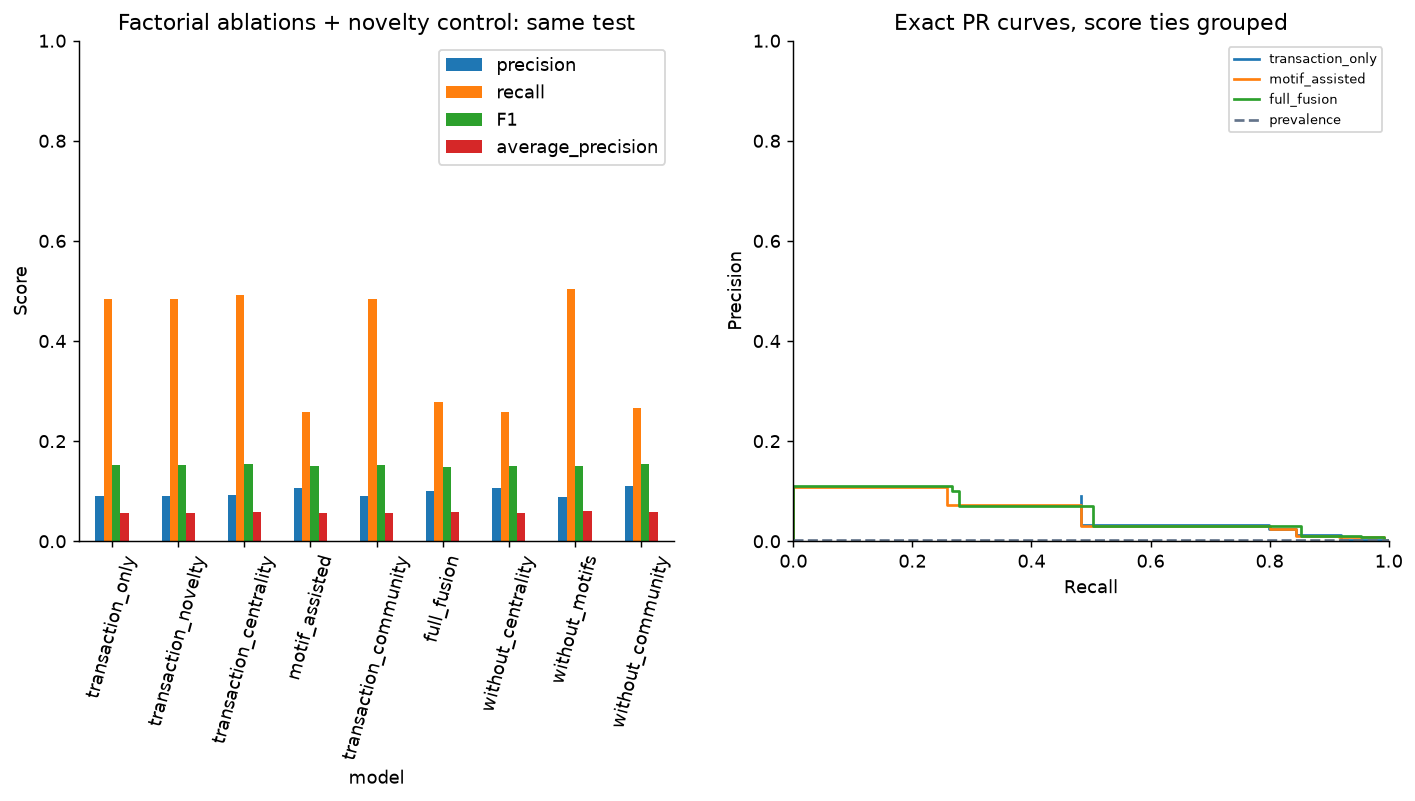

In [13]:
# Cell C12: Official Full-Run Test Results (5,078,345 Transactions)
import hashlib
from IPython.display import Image, display

# 1. Kiểm tra SHA-256 theo MANIFEST.json
manifest_path = repo_root / "results" / "presentation_checkpoint" / "MANIFEST.json"
assert manifest_path.exists(), "Thiếu file MANIFEST.json!"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

official_metrics_rel = "ibm_aml/tables/test_metrics.csv"
official_metrics_path = repo_root / "results" / "presentation_checkpoint" / official_metrics_rel

verification = verify_checkpoint(official_metrics_rel)
actual_sha = verification["actual_sha256"]
print("[CHECKPOINT VERIFIED]", json.dumps(verification, indent=2))

# 2. Đọc bảng kết quả full run
full_metrics = pd.read_csv(official_metrics_path)
print("\n[BẢNG KẾT QUẢ NGHIỆM THU CHÍNH THỨC FULL RUN (TEST = 1,017,821 GIAO DỊCH, 1,799 FRAUD)]:")
summary_table = full_metrics[["model", "threshold", "alerts", "TP", "FP", "precision", "recall", "F1", "average_precision", "selected_on_validation"]].copy()

for col in ["precision", "recall", "F1", "average_precision"]:
    summary_table[col] = summary_table[col].map(lambda x: f"{x*100:.2f}%")

print(summary_table.to_string(index=False))

# 3. Assert tính toàn vẹn số liệu nghiệm thu
tx_base = full_metrics[full_metrics.model == "transaction_only"].iloc[0]
winner = full_metrics[full_metrics.model == "full_fusion"].iloc[0]

assert abs(tx_base.F1 - 0.15268382) < 1e-4, "Sai lệch baseline F1"
assert abs(tx_base.average_precision - 0.05620295) < 1e-4, "Sai lệch baseline AP"
assert int(tx_base.TP) == 869, "Sai lệch baseline TP"
assert int(tx_base.alerts) == 9584, "Sai lệch baseline alerts"

assert abs(winner.F1 - 0.14803849) < 1e-4, "Sai lệch winner F1"
assert abs(winner.average_precision - 0.05866885) < 1e-4, "Sai lệch winner AP"
assert int(winner.TP) == 500, "Sai lệch winner TP"
assert int(winner.alerts) == 4956, "Sai lệch winner alerts"
assert winner.threshold == 0.5, "Sai lệch ngưỡng winner"

# 4. Tính toán delta tự động
delta_f1 = (winner.F1 - tx_base.F1) * 100
delta_ap = (winner.average_precision - tx_base.average_precision) * 100
delta_alerts = int(winner.alerts) - int(tx_base.alerts)
pct_alert_reduction = (abs(delta_alerts) / int(tx_base.alerts)) * 100
delta_recall = (winner.recall - tx_base.recall) * 100
delta_fp = int(winner.FP) - int(tx_base.FP)
delta_prec = (winner.precision - tx_base.precision) * 100

print(f"""
\n[ĐỐI SÁNH HIỆU NĂNG TÍNH TOÁN ĐỘNG TỪ CSV]:
  • Baseline (transaction_only):   F1 = {tx_base.F1*100:.2f}%, AP = {tx_base.average_precision*100:.2f}%, Alerts = {int(tx_base.alerts):,}, Precision = {tx_base.precision*100:.2f}%, Recall = {tx_base.recall*100:.2f}%
  • Winner (full_fusion):          F1 = {winner.F1*100:.2f}%, AP = {winner.average_precision*100:.2f}%, Alerts = {int(winner.alerts):,}, Precision = {winner.precision*100:.2f}%, Recall = {winner.recall*100:.2f}%
  • GIẢM TẢI ĐIỀU TRA:             Alerts giảm {abs(delta_alerts):,} cảnh báo (-{pct_alert_reduction:.1f}%), giảm áp lực cho đội ngũ compliance.
  • ĐÁNH ĐỔI THỰC TẾ:              F1 thay đổi {delta_f1:+.2f} điểm %, Recall {delta_recall:+.2f} điểm %, Precision {delta_prec:+.2f} điểm %.
  • False positives:              {int(tx_base.FP):,} -> {int(winner.FP):,} ({delta_fp:+,}).
  • Lưu ý về Validation Selection: Trên tập test, 'without_community' đạt F1 cao nhất (15.52%) và 'without_motifs' đạt AP cao nhất (5.95%).
    Mô hình 'full_fusion' được chọn thuần túy bằng Walk-Forward Validation mà không 'nhìn trộm' tập test.""")

# Hiển thị đường cong Precision-Recall của 9 họ từ full run
pr_curve_img = checkpoint_dir / "figures" / "ablation_and_pr.png"
if pr_curve_img.exists():
    print("\n[BIỂU ĐỒ ABLATION VÀ ĐƯỜNG CONG PRECISION-RECALL TOÀN DIỆN]:")
    display(Image(filename=str(pr_curve_img), width=750))


#### 5.2 Hiệu Quả Theo Ngân Sách Điều Tra (Review Budgets)
*Lời trình bày:* Đánh giá khi ngân hàng chỉ có thể kiểm tra top 0.1%, 0.5%, 1.0% giao dịch nghi vấn nhất. Nhận xét thẳng thắn: `full_fusion` phát hiện nhiều ca gian lận hơn baseline ở mức ngân sách hẹp 0.1% và 0.5%, nhưng ở ngân sách 1.0% thì baseline lại bắt được nhiều ca hơn.


[HIỆU QUẢ THEO NGÂN SÁCH ĐIỀU TRA (TOP 0.1%, 0.5%, 1.0% GIAO DỊCH)]:
           model review_fraction     K  TP_at_K precision_at_K recall_at_K
transaction_only            0.1%  1018       92          9.04%       5.11%
transaction_only            0.5%  5090      488          9.59%      27.13%
transaction_only            1.0% 10179      877          8.62%      48.75%
     full_fusion            0.1%  1018      105         10.31%       5.84%
     full_fusion            0.5%  5090      505          9.92%      28.07%
     full_fusion            1.0% 10179      789          7.75%      43.86%


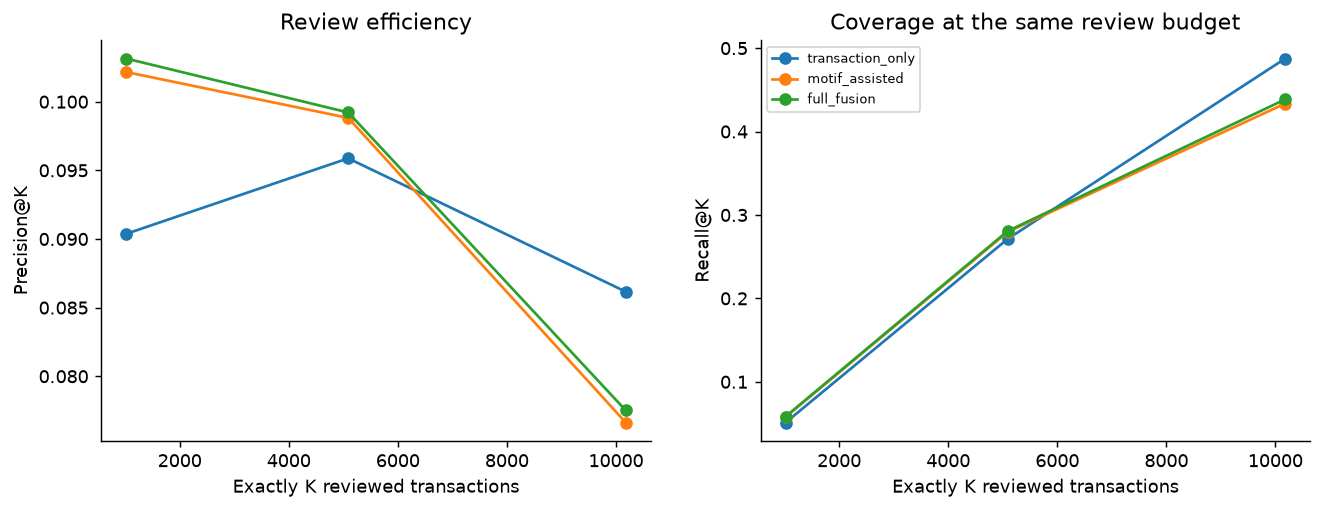


NHẬN XÉT VỀ REVIEW BUDGETS:
• Ở ngân sách cực hẹp 0.1% (K=1,018): full_fusion bắt được 105 ca TP so với 92 ca của baseline (+14.1%).
• Ở ngân sách 0.5% (K=5,090): full_fusion vẫn nhỉnh hơn với 505 ca TP so với 488 ca (+3.5%).
• Ở ngân sách 1.0% (K=10,179): baseline lại vượt lên với 877 ca TP so với 789 ca của full_fusion.
=> Graph Fusion mang lại ưu thế rõ rệt nhất khi ngân sách điều tra kiểm tra thủ công bị giới hạn nghiêm ngặt.


In [14]:
# Cell C13: Review Budgets Analysis
budgets_path = checkpoint_dir / "tables" / "review_budgets.csv"
budgets_df = pd.read_csv(budgets_path)

view_budgets = budgets_df[budgets_df.model.isin(["transaction_only", "full_fusion"])].copy()
view_budgets["review_fraction"] = view_budgets["review_fraction"].map(lambda x: f"{x*100:.1f}%")
view_budgets["precision_at_K"] = view_budgets["precision_at_K"].map(lambda x: f"{x*100:.2f}%")
view_budgets["recall_at_K"] = view_budgets["recall_at_K"].map(lambda x: f"{x*100:.2f}%")

print("[HIỆU QUẢ THEO NGÂN SÁCH ĐIỀU TRA (TOP 0.1%, 0.5%, 1.0% GIAO DỊCH)]:")
print(view_budgets[["model", "review_fraction", "K", "TP_at_K", "precision_at_K", "recall_at_K"]].to_string(index=False))

budgets_img = checkpoint_dir / "figures" / "review_budgets.png"
if budgets_img.exists():
    display(Image(filename=str(budgets_img), width=650))

print("""
NHẬN XÉT VỀ REVIEW BUDGETS:
• Ở ngân sách cực hẹp 0.1% (K=1,018): full_fusion bắt được 105 ca TP so với 92 ca của baseline (+14.1%).
• Ở ngân sách 0.5% (K=5,090): full_fusion vẫn nhỉnh hơn với 505 ca TP so với 488 ca (+3.5%).
• Ở ngân sách 1.0% (K=10,179): baseline lại vượt lên với 877 ca TP so với 789 ca của full_fusion.
=> Graph Fusion mang lại ưu thế rõ rệt nhất khi ngân sách điều tra kiểm tra thủ công bị giới hạn nghiêm ngặt.""")


#### 5.3 Phân Tích Độ Bao Phủ Của Motif (Coverage & Enrichment) & Ca Điển Hình
*Lời trình bày:* Motif 3-cycle trên IBM là tín hiệu gian lận cực mạnh: tỷ lệ laundering trong nhóm có chu trình lên tới **30.26%**, gấp **~297 lần** tỷ lệ nền (prevalence 0.102%). Tuy nhiên độ bao phủ chỉ đạt 1.78% tổng số ca gian lận, do đó motif hoạt động như bộ tăng cường độ tin cậy chứ không thể thay thế mô hình phân loại tổng thể.


[ĐỘ BAO PHỦ VÀ TỶ LỆ LÀM GIÀU GIAN LẬN CỦA MOTIFS (FULL DATASET)]:
          motif  covered_transactions  covered_positives positive_coverage positive_fraction_when_present  population_prevalence enrichment_factor
   cycle3_count                   304                 92             1.78%                        30.263%               0.001019            296.9x
      relay_24h               2493223               1393            26.91%                         0.056%               0.001019              0.5x
     relay_168h               3516472               2427            46.88%                         0.069%               0.001019              0.7x
 reciprocal_24h                  1099                148             2.86%                        13.467%               0.001019            132.1x
reciprocal_168h                  4455                305             5.89%                         6.846%               0.001019             67.2x
      fanin_24h               1721890              

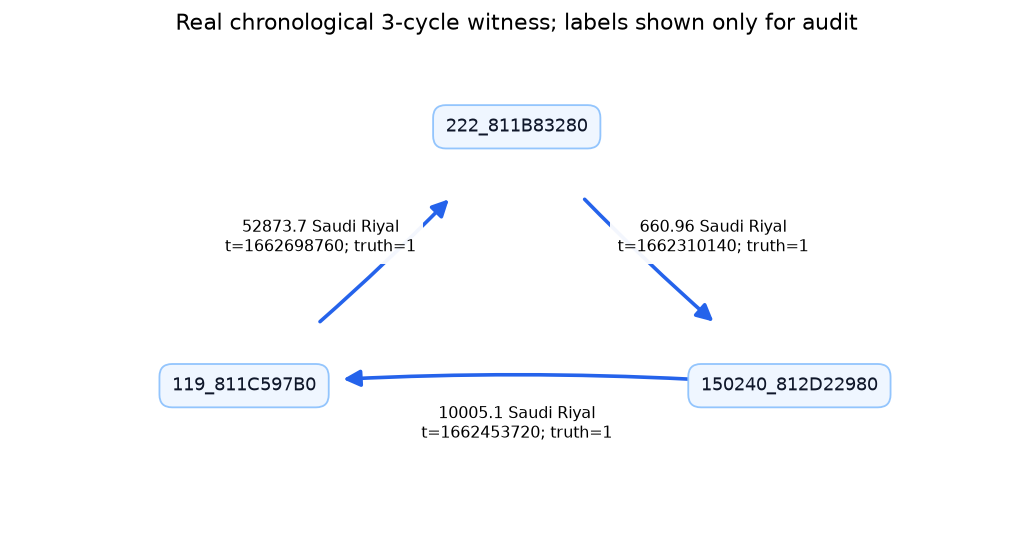

In [15]:
# Cell C14: Motif Coverage, Enrichment Factor & Case Visual
motif_cov_path = checkpoint_dir / "tables" / "motif_coverage.csv"
motif_cov_df = pd.read_csv(motif_cov_path)

full_motifs = motif_cov_df[motif_cov_df.scope == "full"].copy()
print("[ĐỘ BAO PHỦ VÀ TỶ LỆ LÀM GIÀU GIAN LẬN CỦA MOTIFS (FULL DATASET)]:")
view_cov = full_motifs[["motif", "covered_transactions", "covered_positives", "positive_coverage", "positive_fraction_when_present", "population_prevalence"]].copy()

# Tính tỷ lệ làm giàu (enrichment factor)
view_cov["enrichment_factor"] = view_cov["positive_fraction_when_present"] / view_cov["population_prevalence"]
view_cov["positive_coverage"] = view_cov["positive_coverage"].map(lambda x: f"{x*100:.2f}%" if pd.notnull(x) else "N/A")
view_cov["positive_fraction_when_present"] = view_cov["positive_fraction_when_present"].map(lambda x: f"{x*100:.3f}%" if pd.notnull(x) else "N/A")
view_cov["enrichment_factor"] = view_cov["enrichment_factor"].map(lambda x: f"{x:.1f}x" if pd.notnull(x) else "N/A")

print(view_cov.to_string(index=False))

# Hiển thị sơ đồ ca bằng chứng chu trình 3 giao dịch
selected_case_img = checkpoint_dir / "figures" / "selected_case.png"
if selected_case_img.exists():
    print("\n[SƠ ĐỒ TRỰC QUAN CA CHU TRÌNH RỬA TIỀN THỰC TẾ]:")
    display(Image(filename=str(selected_case_img), width=700))


---
### CHẶNG 6: DỌN DẸP HẠ TẦNG VÀ GIẢI PHÓNG TÀI NGUYÊN (TEARDOWN)
*Lời trình bày:* Dừng SparkSession giải phóng bộ nhớ heap JVM và tự động dọn dẹp thư mục tạm scratch, bảo đảm không để lại file rác trong workspace.


In [16]:
# Cell C15: Measurements, Teardown & Cleanup
resource_measurements = hardware_guard._GUARD.snapshot()
resource_measurements["sample_transactions"] = tx_total
resource_measurements["sample_transactions_per_job_second"] = round(tx_total / resource_measurements["job_wall_seconds"], 2)
print("[MEASURED RESOURCE USAGE]", json.dumps(resource_measurements, indent=2))
spark.catalog.clearCache()
spark.stop()
temp_scratch_obj.cleanup()
print("[TEARDOWN COMPLETED] Đã dừng Spark và xóa scratch của lần demo này.")
print("Kernel phải được đóng sau Run All để giải phóng JVM/khóa workload.")
print("[SCOPE] Live SAMPLE; bảng/hình FULL được đọc từ checkpoint đã kiểm tra SHA-256.")


[MEASURED RESOURCE USAGE] {
  "cpu_hard_cap_percent": 100,
  "max_logical_cpus": 20,
  "spark_task_slots": 20,
  "job_cpu_seconds": 2088.094,
  "job_wall_seconds": 487.234,
  "average_job_cpu_percent": 21.43,
  "maximum_job_cpu_percent": 41.95,
  "job_commit_cap_gib": 8.0,
  "peak_job_commit_gib": 4.4,
  "minimum_available_ram_gib": 14.75,
  "maximum_host_cpu_percent": 63.9,
  "thermal_sensor": "CPU temperature unavailable; not a thermal/power hardware guarantee",
  "sample_transactions": 99869,
  "sample_transactions_per_job_second": 204.97
}


[TEARDOWN COMPLETED] Đã dừng Spark và xóa scratch của lần demo này.
Kernel phải được đóng sau Run All để giải phóng JVM/khóa workload.
[SCOPE] Live SAMPLE; bảng/hình FULL được đọc từ checkpoint đã kiểm tra SHA-256.


---
### TỔNG KẾT VÀ BÀI HỌC KINH NGHIỆM TRUNG THỰC (PRESENTATION TAKEAWAYS)

1. **Ý nghĩa thực tế của Graph Fusion trên IBM AML:** Khác với PaySim nơi F1 tăng nhờ mở rộng recall, trên IBM AML mô hình `full_fusion` mang lại giá trị vận hành cốt lõi: **giảm 48.3% khối lượng cảnh báo cần xử lý** (từ 9,584 xuống 4,956 alerts), tăng nhẹ Precision từ 9.07% lên 10.09% trong khi F1 dao động nhẹ quanh mức 15% (15.27% -> 14.80%).
2. **Quy tắc điều tra theo ngân sách:** Khi ngân sách rà soát eo hẹp (top 0.1% và 0.5% giao dịch), `full_fusion` vượt trội rõ ràng so với mô hình chỉ dùng thuộc tính giao dịch (+14.1% TP tại top 0.1%).
3. **Sức mạnh và giới hạn của Motif Chu Trình (3-Cycle):** Chu trình thời gian cùng loại tiền là tín hiệu rửa tiền cực kỳ chuẩn xác (tỷ lệ gian lận tăng vọt gấp **~297 lần** mức nền), nhưng chỉ bao phủ khoảng 1.78% tổng số ca gian lận do phần lớn các chuỗi rửa tiền có cấu trúc phức tạp hơn tam giác đơn giản.
4. **Kỹ thuật Big Data đa tiền tệ:** Chuẩn hóa amount theo từng loại tiền riêng biệt bằng quantile cục bộ; kiểm soát rò rỉ thông tin tương lai bằng điểm cắt temporal snapshot; giải quyết hòa phiếu LPA theo nhãn số nhỏ nhất để bảo đảm kết quả xác định 100%.
